# Onion service correlation: client Guard vs service Guard 

**Question.** If an observer sees only the Guard of the client and the Guard of the onion service, can the two sides be linked by timing?

**Method.**
1. Group the packets of each Guard into *bursts* (same direction, gap <= 0.1 s), keep bursts >= 1000 bytes.
2. Pair client bursts with service bursts that start within a lag window. Pairing is **strictly one-to-one**.
3. Compare the real result with two controls that cannot contain a true correspondence:
   * **time shift**: service trace of the same run moved by 10-50 s;
   * **cross-run**: service trace of a *different* run j, aligned to the start of run i. It keeps a realistic burst structure.
4. Check which requests of the client log are covered by at least one pair, for real data and controls.
5. Sensitivity to the lag window and to packet direction.
6. Diagnose the extra client bursts in run_02 / run_03 (bursts inside vs between requests, packets per peer, uncovered requests).
7. Robustness checks: remove the packets exchanged directly between the two Guards, and vary the minimum burst size.

All numbers are timing statistics, not precision/recall and not proof of de-anonymisation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Configuration (change here when the network is recreated) -----------
CLIENT_GUARD_IP  = "10.5.184.229"   # relayngpufjeq
SERVICE_GUARD_IP = "10.5.237.145"   # relaysgufrlnh
RUNS = ["run_01", "run_02", "run_03", "run_04", "run_05"]

BURST_GAP       = 0.1     # s
MIN_BURST_BYTES = 1000
LAG_MIN, LAG_MAX = -0.1, 0.5      # main lag window (s): service start - client start
SHIFTS = [10, 20, 30, 40, 50]     # s, time-shift control

RESULTS = next(p for p in [Path("results"), Path("experiments/onion-correlation/results")] if p.is_dir())
print("Results:", RESULTS.resolve())

Results: /home/elenapozzebon/tor-network-security-project/experiments/onion-correlation/results


## 1. Load packets, bursts and request logs

In [2]:
def load_packets(csv_path, guard_ip):
    df = pd.read_csv(csv_path)
    df.columns = ["time", "size", "src", "dst"]
    df = df.dropna(subset=["src", "dst"]).sort_values("time").reset_index(drop=True)
    df["dir"]  = np.where(df["src"] == guard_ip, 1, -1)            # +1 leaves the Guard, -1 enters it
    df["peer"] = np.where(df["src"] == guard_ip, df["dst"], df["src"])
    return df

def make_bursts(pk, min_bytes=None):
    new = (pk["time"].diff() > BURST_GAP) | (pk["dir"] != pk["dir"].shift())
    b = pk.assign(burst=new.cumsum()).groupby("burst").agg(
        start=("time", "min"), bytes=("size", "sum"), dir=("dir", "first"), packets=("size", "count"))
    threshold = MIN_BURST_BYTES if min_bytes is None else min_bytes
    return b[b["bytes"] >= threshold].reset_index(drop=True)

def load_requests(run):
    req = pd.read_csv(RESULTS / run / "client_requests_log.csv")
    return req[req["success"]].reset_index(drop=True)

packets, bursts, requests = {}, {}, {}
for run in RUNS:
    folder = RESULTS / run / "analysis" / "window_5s"
    packets[run] = {"client":  load_packets(folder / "client_metadata.csv",  CLIENT_GUARD_IP),
                    "service": load_packets(folder / "service_metadata.csv", SERVICE_GUARD_IP)}
    bursts[run]  = {side: make_bursts(packets[run][side]) for side in ("client", "service")}
    requests[run] = load_requests(run)
    print(run, "client bursts:", len(bursts[run]["client"]), "| service bursts:", len(bursts[run]["service"]),
          "| requests:", len(requests[run]))

# time of the first request of each run, used to align runs with each other
T0 = {run: requests[run]["timestamp_start"].min() for run in RUNS}

run_01 client bursts: 179 | service bursts: 173 | requests: 100
run_02 client bursts: 413 | service bursts: 199 | requests: 100
run_03 client bursts: 400 | service bursts: 198 | requests: 100
run_04 client bursts: 218 | service bursts: 314 | requests: 100
run_05 client bursts: 298 | service bursts: 493 | requests: 100


## 2. One-to-one pairing

Client bursts are scanned in time order. Each takes the **closest still-unused** service burst inside the lag window
(optionally with a direction rule). Unlike the first version, a service burst can never be claimed twice.

`direction`: `any` = ignore, `same` = both bursts must have the same direction, `opposite` = opposite directions.

In [3]:
def pair_bursts(client, service, lag_min=LAG_MIN, lag_max=LAG_MAX, direction="any", shift=0.0):
    c_start, c_dir = client["start"].to_numpy(), client["dir"].to_numpy()
    order = np.argsort(service["start"].to_numpy() + shift)
    s_start = service["start"].to_numpy()[order] + shift
    s_dir = service["dir"].to_numpy()[order]
    used = np.zeros(len(s_start), dtype=bool)
    out = []
    for i in np.argsort(c_start):
        lo = np.searchsorted(s_start, c_start[i] + lag_min, side="left")
        hi = np.searchsorted(s_start, c_start[i] + lag_max, side="right")
        idx = np.arange(lo, hi)
        idx = idx[~used[idx]]
        if direction == "same":
            idx = idx[s_dir[idx] == c_dir[i]]
        elif direction == "opposite":
            idx = idx[s_dir[idx] != c_dir[i]]
        if idx.size == 0:
            continue
        j = idx[np.argmin(np.abs(s_start[idx] - c_start[i]))]
        used[j] = True
        out.append((c_start[i], s_start[j], s_start[j] - c_start[i]))
    return pd.DataFrame(out, columns=["client_start", "service_start", "lag"])

def covered(pairs, req, lag_min=LAG_MIN, lag_max=LAG_MAX):
    """Requests with at least one pair whose client burst starts inside [start+lag_min, end+lag_max]."""
    starts = np.sort(pairs["client_start"].to_numpy())
    lo = np.searchsorted(starts, req["timestamp_start"].to_numpy() + lag_min, side="left")
    hi = np.searchsorted(starts, req["timestamp_end"].to_numpy() + lag_max, side="right")
    return int((hi > lo).sum())

## 3. Real data vs controls

For each run: real pairs, the time-shift control (mean over 5 shifts) and the cross-run control (service of each other run j != i, aligned by the first request, mean over 4 runs). Coverage is computed in the same way for all three.

In [4]:
def evaluate(lag_min=LAG_MIN, lag_max=LAG_MAX, direction="any", data=None):
    B = bursts if data is None else data   # data: alternative burst tables (robustness checks)
    rows = []
    for ri in RUNS:
        c, s, req = B[ri]["client"], B[ri]["service"], requests[ri]
        real = pair_bursts(c, s, lag_min, lag_max, direction)
        shifted = [pair_bursts(c, s, lag_min, lag_max, direction, shift=sh) for sh in SHIFTS]
        cross = [pair_bursts(c, B[rj]["service"], lag_min, lag_max, direction, shift=T0[ri] - T0[rj])
                 for rj in RUNS if rj != ri]
        rows.append({
            "run": ri, "client_bursts": len(c), "service_bursts": len(s), "n_req": len(req),
            "pairs": len(real),
            "pairs_shift": np.mean([len(p) for p in shifted]),
            "pairs_cross": np.mean([len(p) for p in cross]),
            "cov_real":  covered(real, req, lag_min, lag_max),
            "cov_shift": np.mean([covered(p, req, lag_min, lag_max) for p in shifted]),
            "cov_cross": np.mean([covered(p, req, lag_min, lag_max) for p in cross]),
            "median_lag_s": real["lag"].median(),
        })
        rows[-1]["_lags"] = real["lag"].to_numpy()
    return pd.DataFrame(rows)

def present(res):
    t = pd.DataFrame({
        "run": res["run"],
        "client_bursts": res["client_bursts"],
        "service_bursts": res["service_bursts"],
        "pairs": res["pairs"],
        "paired_%": (100 * res["pairs"] / res["client_bursts"]).round(1),
        "shift_%":  (100 * res["pairs_shift"] / res["client_bursts"]).round(1),
        "cross_run_%": (100 * res["pairs_cross"] / res["client_bursts"]).round(1),
        "median_lag_s": res["median_lag_s"].round(4),
        "req_covered": res["cov_real"].astype(str) + "/" + res["n_req"].astype(str),
        "req_covered_shift": res["cov_shift"].round(1),
        "req_covered_cross": res["cov_cross"].round(1),
    })
    tot = res[["client_bursts", "service_bursts", "pairs", "pairs_shift", "pairs_cross",
               "cov_real", "cov_shift", "cov_cross", "n_req"]].sum()
    t.loc[len(t)] = ["ALL", tot.client_bursts, tot.service_bursts, tot.pairs,
                     round(100 * tot.pairs / tot.client_bursts, 1),
                     round(100 * tot.pairs_shift / tot.client_bursts, 1),
                     round(100 * tot.pairs_cross / tot.client_bursts, 1),
                     round(float(np.median(np.concatenate(res["_lags"].to_list()))), 4),
                     f"{int(tot.cov_real)}/{int(tot.n_req)}", round(tot.cov_shift, 1), round(tot.cov_cross, 1)]
    return t

main = evaluate()
summary = present(main)
summary.to_csv(RESULTS / "onion_summary.csv", index=False)
summary

,run,client_bursts,service_bursts,pairs,paired_%,shift_%,cross_run_%,median_lag_s,req_covered,req_covered_shift,req_covered_cross
0,run_01,179.0,173.0,167.0,93.3,9.7,12.6,-0.0041,82/100,8.8,11.0
1,run_02,413.0,199.0,177.0,42.9,8.1,11.8,-0.0003,83/100,15.8,17.5
2,run_03,400.0,198.0,180.0,45.0,6.1,9.9,-0.0000,90/100,12.2,13.2
3,run_04,218.0,314.0,174.0,79.8,10.4,15.0,-0.0003,86/100,11.4,15.5
4,run_05,298.0,493.0,176.0,59.1,9.3,10.1,-0.0003,88/100,13.2,14.5
5,ALL,1508.0,1377.0,874.0,58.0,8.3,11.5,-0.0008,429/500,61.4,71.8


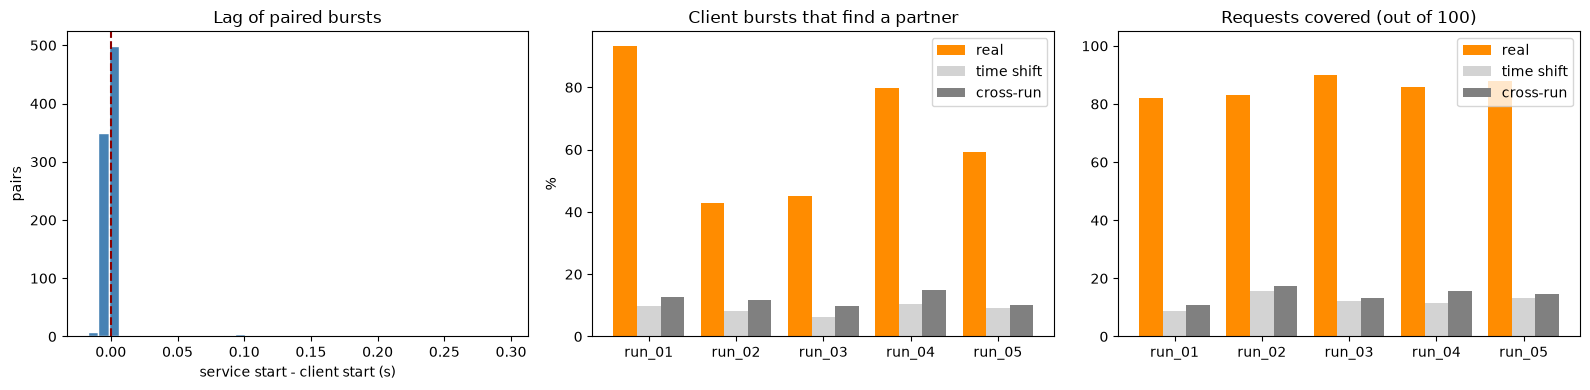

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
lags = np.concatenate(main["_lags"].to_list())
ax[0].hist(lags, bins=40, color="steelblue", edgecolor="white")
ax[0].axvline(0, color="darkred", ls="--")
ax[0].set(title="Lag of paired bursts", xlabel="service start - client start (s)", ylabel="pairs")

x, per = np.arange(len(main)), summary.iloc[:-1]
ax[1].bar(x - 0.27, per["paired_%"], 0.27, label="real", color="darkorange")
ax[1].bar(x,        per["shift_%"],  0.27, label="time shift", color="lightgray")
ax[1].bar(x + 0.27, per["cross_run_%"], 0.27, label="cross-run", color="gray")
ax[1].set_xticks(x, per["run"]); ax[1].set(title="Client bursts that find a partner", ylabel="%"); ax[1].legend()

n = main["n_req"]
ax[2].bar(x - 0.27, main["cov_real"],  0.27, label="real", color="darkorange")
ax[2].bar(x,        main["cov_shift"], 0.27, label="time shift", color="lightgray")
ax[2].bar(x + 0.27, main["cov_cross"], 0.27, label="cross-run", color="gray")
ax[2].set_xticks(x, main["run"]); ax[2].set(title="Requests covered (out of 100)", ylim=(0, 105)); ax[2].legend()
plt.tight_layout(); plt.show()

## 4. Sensitivity: lag window and packet direction

If the result barely changes with a much tighter window, the wide +0.5 s margin is not needed. The direction rule tells whether using packet direction adds information (`same` / `opposite` is relative to each Guard's own IP). Values are pooled over the five runs.

In [6]:
rows = []
for (lmin, lmax) in [(-0.1, 0.5), (-0.05, 0.05), (-0.02, 0.02)]:
    for direction in ["any", "same", "opposite"]:
        r = evaluate(lmin, lmax, direction)
        t = r[["client_bursts", "pairs", "pairs_shift", "pairs_cross", "cov_real", "cov_shift", "cov_cross", "n_req"]].sum()
        rows.append({
            "lag_window_s": f"[{lmin}, {lmax}]", "direction": direction,
            "paired_%": round(100 * t.pairs / t.client_bursts, 1),
            "shift_%": round(100 * t.pairs_shift / t.client_bursts, 1),
            "cross_run_%": round(100 * t.pairs_cross / t.client_bursts, 1),
            "req_covered_%": round(100 * t.cov_real / t.n_req, 1),
            "req_covered_cross_%": round(100 * t.cov_cross / t.n_req, 1),
        })
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(RESULTS / "onion_sensitivity.csv", index=False)
sensitivity

,lag_window_s,direction,paired_%,shift_%,cross_run_%,req_covered_%,req_covered_cross_%
0,"[-0.1, 0.5]",any,58.0,8.3,11.5,85.8,14.4
1,"[-0.1, 0.5]",same,58.0,8.3,11.5,85.8,14.4
2,"[-0.1, 0.5]",opposite,58.0,8.3,11.5,85.8,14.4
3,"[-0.05, 0.05]",any,57.9,1.5,2.6,85.8,3.1
4,"[-0.05, 0.05]",same,57.9,1.5,2.6,85.8,3.1
5,"[-0.05, 0.05]",opposite,57.9,1.5,2.6,85.8,3.1
6,"[-0.02, 0.02]",any,57.8,0.8,1.5,85.8,1.8
7,"[-0.02, 0.02]",same,57.8,0.8,1.5,85.8,1.7
8,"[-0.02, 0.02]",opposite,57.7,0.8,1.5,85.8,1.8


## 5. Why does the client Guard have extra bursts in some runs?

Compare bursts that start **inside** a request window (request interval extended by the lag margins) with bursts **between** requests, plus the number of distinct peers seen at the Guard. Bursts between requests are background traffic: Tor control cells, circuit (re)builds, keep-alives, or other circuits through the same relay.

In [7]:
def in_request_window(starts, req):
    """True for every burst start (in the original order) inside a request window."""
    lo = req["timestamp_start"].to_numpy() + LAG_MIN
    hi = req["timestamp_end"].to_numpy() + LAG_MAX
    return ((starts[:, None] >= lo[None, :]) & (starts[:, None] <= hi[None, :])).any(axis=1)

diag = []
for run in RUNS:
    for side in ("client", "service"):
        b = bursts[run][side]
        inside = in_request_window(b["start"].to_numpy(), requests[run])
        pk = packets[run][side]
        diag.append({
            "run": run, "side": side, "bursts": len(b),
            "in_request_window": int(inside.sum()),
            "between_requests": int((~inside).sum()),
            "bursts_per_request": round(inside.sum() / len(requests[run]), 2),
            "median_bytes_inside": int(b.loc[inside, "bytes"].median()) if inside.any() else None,
            "median_bytes_between": int(b.loc[~inside, "bytes"].median()) if (~inside).any() else None,
            "distinct_peer_IPs": pk["peer"].nunique(),
            "packets": len(pk),
        })
diagnostics = pd.DataFrame(diag)
diagnostics.to_csv(RESULTS / "onion_diagnostics.csv", index=False)
diagnostics

,run,side,bursts,in_request_window,between_requests,bursts_per_request,median_bytes_inside,median_bytes_between,distinct_peer_IPs,packets
0,run_01,client,179,179,0,1.79,1122,NaN,11,1656
1,run_01,service,173,167,6,1.67,1122,1252.0,11,1482
2,run_02,client,413,393,20,3.93,1194,1671.0,10,3921
3,run_02,service,199,179,20,1.79,1194,1297.0,10,1738
4,run_03,client,400,400,0,4.00,1122,NaN,11,2979
5,run_03,service,198,180,18,1.80,1122,1683.0,10,1520
6,run_04,client,218,218,0,2.18,1122,NaN,10,1650
7,run_04,service,314,314,0,3.14,1122,NaN,10,2439
8,run_05,client,298,295,3,2.95,1194,1216.0,11,2606
9,run_05,service,493,263,230,2.63,1122,3318.0,10,2806


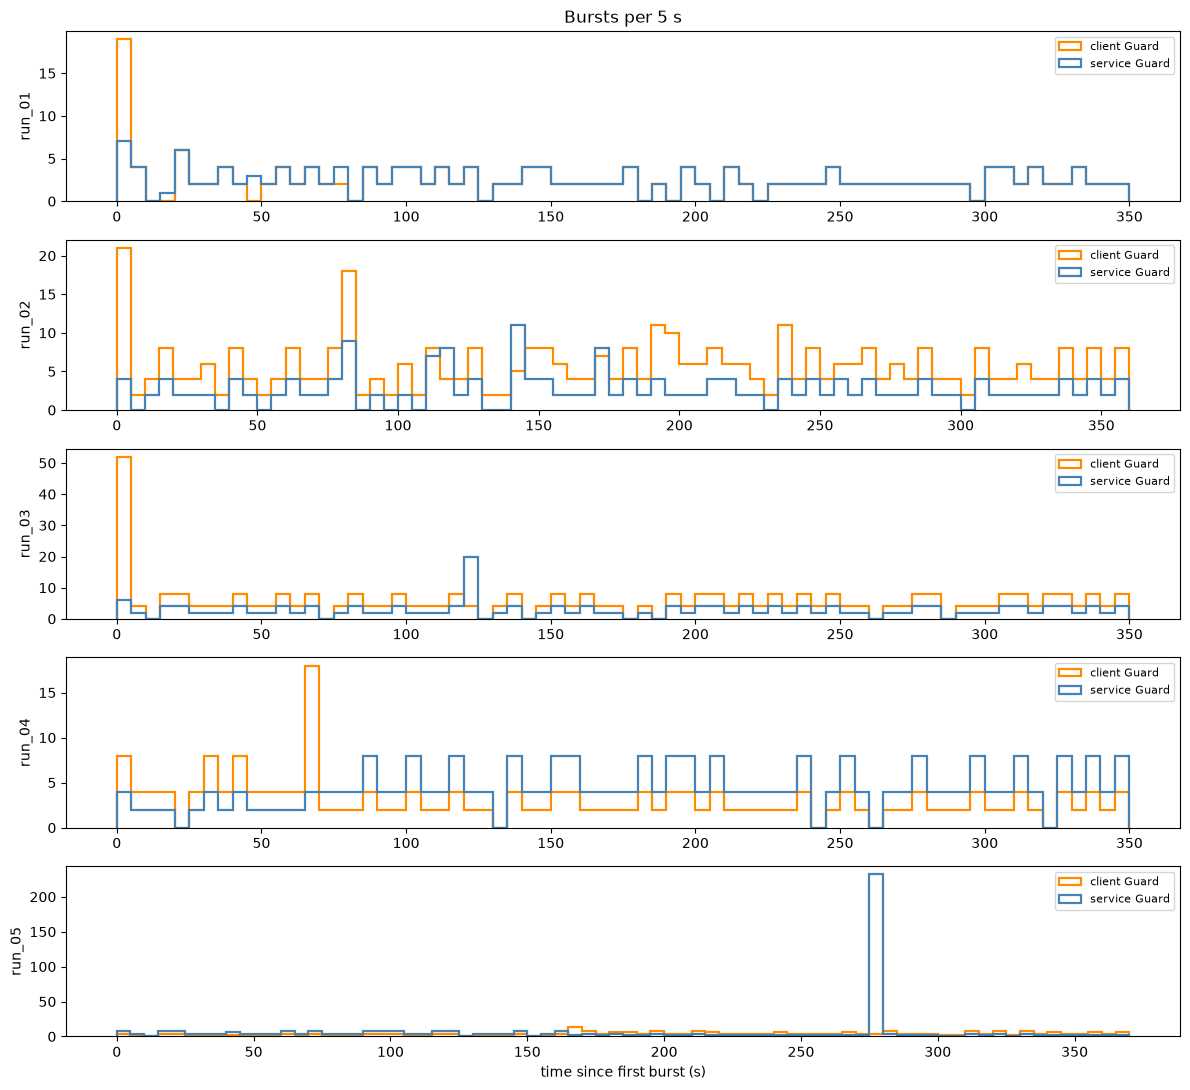

In [8]:
# Bursts per 5-second bin over the run: extra background shows up as a higher or irregular client line
fig, axes = plt.subplots(len(RUNS), 1, figsize=(12, 2.2 * len(RUNS)), sharex=False)
for ax, run in zip(axes, RUNS):
    t0 = min(bursts[run]["client"]["start"].min(), bursts[run]["service"]["start"].min())
    for side, color in (("client", "darkorange"), ("service", "steelblue")):
        s = bursts[run][side]["start"] - t0
        ax.hist(s, bins=np.arange(0, s.max() + 5, 5), histtype="step", lw=1.6, color=color, label=f"{side} Guard")
    ax.set(ylabel=run); ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("time since first burst (s)"); axes[0].set_title("Bursts per 5 s")
plt.tight_layout(); plt.show()

What the diagnostics showed on the real data:

* **Not background traffic between requests.** The extra client bursts of run_02 / run_03 fall *inside* the request windows (`between_requests` is 20 and 0), with the same burst size as the others. Each request produces about 4 bursts at the client Guard against about 1.8 at the service Guard.
* **More traffic with other relays, not with the client.** Section 6.1 shows that in those runs the client Guard exchanges about 2.5 times more packets with other relays than with the client container (ratio about 1 in run_01). This is consistent with the Guard also carrying other circuits, but it is **not confirmed**: check `GETINFO circuit-status` on the containers during a run.
* **Run_05** has a one-off group of about 230 service bursts around 275 s (median about 3.3 kB), cause not determined (check the service container logs).
* A burst count per request different from 1.8 at one side lowers `paired_%` (unpairable bursts in the denominator), while request coverage is less affected.

## 6. Open checks

**6.1 Who talks to each Guard?** Packets per peer IP and run. If the client Guard also carries the service's half of the circuit (e.g. as rendezvous point or middle relay), the service container or the middle relays will show up as heavy peers of the client Guard, which would explain the extra bursts in run_02 / run_03. This is a check, not a conclusion.

In [9]:
def peer_table(side):
    t = pd.concat({run: packets[run][side].groupby("peer").size() for run in RUNS}, axis=1).fillna(0).astype(int)
    return t.sort_values(RUNS[0], ascending=False)

print("Packets per peer at the CLIENT Guard"); display(peer_table("client"))
print("Packets per peer at the SERVICE Guard"); display(peer_table("service"))

Packets per peer at the CLIENT Guard


,run_01,run_02,run_03,run_04,run_05
peer,,,,,
10.5.178.226,808,1053,843,717,837
10.5.182.47,683,48,730,136,4
10.5.215.124,58,26,55,534,782
10.5.214.144,40,60,6,9,931
10.5.143.166,34,1785,644,120,21
10.5.237.145,8,18,657,118,6
10.5.201.132,6,12,3,0,4
10.5.2.120,6,875,14,4,3
10.5.30.22,5,0,4,4,4


Packets per peer at the SERVICE Guard


,run_01,run_02,run_03,run_04,run_05
peer,,,,,
10.5.174.148,710,808,732,712,1086
10.5.182.47,660,27,35,4,110
10.5.143.166,29,729,18,529,404
10.5.214.144,23,61,26,527,836
10.5.30.22,13,0,0,0,0
10.5.215.124,11,8,11,531,296
10.5.77.135,10,56,14,4,17
10.5.184.229,8,18,657,118,6
10.5.117.101,6,12,9,6,26


**6.2 Requests without a linked pair.** For each uncovered request: bursts of at least 1000 bytes and all bursts (any size) in its window, at both Guards. If one side has no big burst in the window, the request is missed because of the size filter; if both have bursts but no pair, the timing rule failed.

In [10]:
rows = []
for run in RUNS:
    req = requests[run]
    real = pair_bursts(bursts[run]["client"], bursts[run]["service"])
    starts = np.sort(real["client_start"].to_numpy())
    all_b = {}
    for s in ("client", "service"):
        pk = packets[run][s]
        new = (pk["time"].diff() > BURST_GAP) | (pk["dir"] != pk["dir"].shift())
        all_b[s] = pk.assign(burst=new.cumsum()).groupby("burst").agg(start=("time", "min"), bytes=("size", "sum"))
    for _, r in req.iterrows():
        lo, hi = r["timestamp_start"] + LAG_MIN, r["timestamp_end"] + LAG_MAX
        if ((starts >= lo) & (starts <= hi)).any():
            continue
        def count(df, min_bytes):
            return int(((df["start"] >= lo) & (df["start"] <= hi) & (df["bytes"] >= min_bytes)).sum())
        rows.append({"run": run, "request_id": int(r["request_id"]),
                     "client_big": count(all_b["client"], MIN_BURST_BYTES), "service_big": count(all_b["service"], MIN_BURST_BYTES),
                     "client_any": count(all_b["client"], 0), "service_any": count(all_b["service"], 0)})
uncovered = pd.DataFrame(rows)
uncovered.to_csv(RESULTS / "onion_uncovered_requests.csv", index=False)
print("Uncovered requests:", len(uncovered))
print("  no big burst on the client side :", int((uncovered["client_big"] == 0).sum()))
print("  no big burst on the service side:", int((uncovered["service_big"] == 0).sum()))
print("  big bursts on both sides, no pair:", int(((uncovered["client_big"] > 0) & (uncovered["service_big"] > 0)).sum()))
uncovered.head(20)

Uncovered requests: 71
  no big burst on the client side : 46
  no big burst on the service side: 71
  big bursts on both sides, no pair: 0


,run,request_id,client_big,service_big,client_any,service_any
0,run_01,5,0,0,13,13
1,run_01,6,0,0,18,13
2,run_01,15,0,0,13,13
3,run_01,16,0,0,13,14
4,run_01,25,0,0,13,15
5,run_01,39,0,0,13,13
6,run_01,48,0,0,13,13
7,run_01,54,0,0,14,13
8,run_01,55,0,0,13,13
9,run_01,57,0,0,13,13


## 7. Robustness checks

**7.1 Direct Guard-to-Guard link.** The packets-per-peer tables (section 6.1) show that in some runs the two Guards exchange packets *with each other* (e.g. run_03: 657 packets). Both captures contain those same packets with the same timestamps, so they pair trivially and could inflate the correlation. Here those packets are removed from both traces and the whole analysis is repeated.

In [11]:
def pooled(r):
    t = r[["client_bursts", "pairs", "pairs_shift", "pairs_cross", "cov_real", "cov_shift", "cov_cross", "n_req"]].sum()
    return {"client_bursts": int(t.client_bursts),
            "paired_%": round(100 * t.pairs / t.client_bursts, 1),
            "shift_%": round(100 * t.pairs_shift / t.client_bursts, 1),
            "cross_run_%": round(100 * t.pairs_cross / t.client_bursts, 1),
            "req_covered_%": round(100 * t.cov_real / t.n_req, 1),
            "req_covered_cross_%": round(100 * t.cov_cross / t.n_req, 1)}

nolink, link_rows = {}, []
for run in RUNS:
    c_pk = packets[run]["client"][packets[run]["client"]["peer"] != SERVICE_GUARD_IP]
    s_pk = packets[run]["service"][packets[run]["service"]["peer"] != CLIENT_GUARD_IP]
    link_rows.append({"run": run,
                      "client_packets_on_link": len(packets[run]["client"]) - len(c_pk),
                      "service_packets_on_link": len(packets[run]["service"]) - len(s_pk)})
    nolink[run] = {"client": make_bursts(c_pk), "service": make_bursts(s_pk)}
print("Packets exchanged directly between the two Guards (removed below):")
display(pd.DataFrame(link_rows))

rows = []
for label, data in [("all packets", None), ("without Guard-to-Guard link", nolink)]:
    for (lmin, lmax) in [(-0.1, 0.5), (-0.05, 0.05)]:
        rows.append({"traffic": label, "lag_window_s": f"[{lmin}, {lmax}]", **pooled(evaluate(lmin, lmax, "any", data=data))})
robust_link = pd.DataFrame(rows)
robust_link.to_csv(RESULTS / "onion_robustness_link.csv", index=False)
display(robust_link)

print("Per run, without the direct link, lag window [-0.05, 0.05]:")
display(present(evaluate(-0.05, 0.05, "any", data=nolink)))

Packets exchanged directly between the two Guards (removed below):


,run,client_packets_on_link,service_packets_on_link
0,run_01,8,8
1,run_02,18,18
2,run_03,657,657
3,run_04,118,118
4,run_05,6,6


,traffic,lag_window_s,client_bursts,paired_%,shift_%,cross_run_%,req_covered_%,req_covered_cross_%
0,all packets,"[-0.1, 0.5]",1508,58.0,8.3,11.5,85.8,14.4
1,all packets,"[-0.05, 0.05]",1508,57.9,1.5,2.6,85.8,3.1
2,without Guard-to-Guard link,"[-0.1, 0.5]",1405,54.9,8.0,10.5,85.8,14.4
3,without Guard-to-Guard link,"[-0.05, 0.05]",1405,54.8,1.6,2.4,85.8,3.1


Per run, without the direct link, lag window [-0.05, 0.05]:


,run,client_bursts,service_bursts,pairs,paired_%,shift_%,cross_run_%,median_lag_s,req_covered,req_covered_shift,req_covered_cross
0,run_01,179.0,173.0,167.0,93.3,2.0,1.7,-0.0041,82/100,1.8,1.5
1,run_02,414.0,201.0,177.0,42.8,2.4,3.2,-0.0004,83/100,5.0,5.8
2,run_03,310.0,107.0,91.0,29.4,0.4,2.3,-0.0027,90/100,1.2,2.5
3,run_04,204.0,299.0,159.0,77.9,1.4,3.3,-0.0005,86/100,1.4,3.5
4,run_05,298.0,493.0,176.0,59.1,1.5,1.2,-0.0004,88/100,2.2,2.2
5,ALL,1405.0,1273.0,770.0,54.8,1.6,2.4,-0.0011,429/500,11.6,15.5


**7.2 Minimum burst size.** Section 6.2 shows that the uncovered requests have no burst of at least 1000 bytes at the service Guard, so request coverage is limited by the size filter. This sweep repeats the analysis (window +/-0.05 s) with other thresholds; the controls show how much of any gain is chance.

In [12]:
rows = []
for mb in [0, 300, 500, 1000, 1500]:
    data = {run: {s: make_bursts(packets[run][s], mb) for s in ("client", "service")} for run in RUNS}
    rows.append({"min_burst_bytes": mb, **pooled(evaluate(-0.05, 0.05, "any", data=data))})
robust_size = pd.DataFrame(rows)
robust_size.to_csv(RESULTS / "onion_robustness_size.csv", index=False)
robust_size

,min_burst_bytes,client_bursts,paired_%,shift_%,cross_run_%,req_covered_%,req_covered_cross_%
0,0,9259,56.3,2.8,4.1,100.0,10.8
1,300,7603,60.2,2.6,3.9,100.0,8.2
2,500,7602,60.2,2.6,3.9,100.0,8.2
3,1000,1508,57.9,1.5,2.6,85.8,3.1
4,1500,87,14.9,0.0,2.0,1.2,0.1


## 8. Limits of this experiment

* **One host, one clock.** All containers run on the same machine with the same clock and almost no network delay, so timing offsets between the two Guards are near zero (median lag ~ 0 s). On the real Tor network, latency and clock differences are much larger.
* **A single tiny page.** The service returns `<h1>Hello Tor</h1>`: every request looks the same, so the traffic is simpler than real browsing.
* **No other users.** One client and one service in a private network, with no real background traffic. The attacker only has to link one pair, not choose among many.
* **Hand-chosen thresholds.** Burst gap (0.1 s), minimum size (1000 bytes) and lag window are not calibrated; the sensitivity table shows how much they matter.
* **Burst size = frame size** at the Guard (TLS/Tor cells included), not HTTP payload size.
* **Request attribution** relies on timestamps; the server log has one-second resolution and bursts are not labelled individually.
* The percentages are **timing statistics**, not precision, recall or accuracy, and they are not proof of de-anonymisation. They show that a timing correlation exists in this setup.